In [1]:
# instalation du package pour telecharger le dataset depuis UCI
!pip install ucimlrepo

In [2]:
import numpy as np # pour les calcule sur les tableaux et matrices
import pandas as pd # pour manipuler les donnees sous forme de dataframe
import matplotlib.pyplot as plt # pour tracer les courbes
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers # bibliotheque pour creer les couches du reseau de neurone
from sklearn.model_selection import train_test_split # pour diviser le dataset en train/val/test
from sklearn.preprocessing import StandardScaler, LabelEncoder # pour normaliser et encoder les labels en chiffres
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

SEED = 42
keras.utils.set_random_seed(SEED) # on fixe le seed pour avoir toujour les meme resultat quand on relance
print("TensorFlow :", tf.__version__)
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11}) # taille par defaut des graphe

TensorFlow : 2.21.0


In [3]:
# on importe la fonction pour recuperer le dataset sur uci
from ucimlrepo import fetch_ucirepo

# on telecharge le dataset Dry Bean (son id c'est 602)
dry_bean = fetch_ucirepo(id=602)

# X_df contient les 16 caracteristique geometrique des haricots
X_df = dry_bean.data.features

# y_raw c'est la colonne cible (les especes de haricots), ravel() la met en 1D
y_raw = dry_bean.data.targets.values.ravel()

# on affiche la taille de X et y pour verifier
print("X :", X_df.shape)
print("y :", y_raw.shape)

# voir les types des variables (int ou float)
print("\nTypes des colonnes :")
print(X_df.dtypes)

# on verifie si ya des valeur manquante dans le dataset
print("\nValeurs manquantes :", int(X_df.isna().sum().sum()))

# on regarde combien il y a de lignes en doublon
print("Doublons exacts dans X :", int(X_df.duplicated().sum()))

# voir la repartition des classes (on voit que DERMASON est beaucoup plus present que BOMBAY)
print("\nClasses et effectifs :")
print(pd.Series(y_raw).value_counts())

# afficher les 5 premiere lignes du tableau
X_df.head()

X : (13611, 16)
y : (13611,)

Types des colonnes :
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRatio        float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
Roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
dtype: object

Valeurs manquantes : 0
Doublons exacts dans X : 68

Classes et effectifs :
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


In [4]:
# on convertit en float32 parce que TensorFlow travaille mieux avec ce format
X = X_df.values.astype("float32")

# LabelEncoder transforme les noms des haricots (texte) en chiffre de 0 a 6
encoder = LabelEncoder()
y = encoder.fit_transform(y_raw)

# on garde la liste des noms de classes pour l'affichage plus tard
class_names = list(encoder.classes_)

# nombre d'entrees (16) et nombre de classes (7)
n_features = X.shape[1]
n_classes = len(class_names)

# afficher quel chiffre correspond a quelle classe
print("Correspondance indice -> classe :", dict(enumerate(class_names)))
print("Entrées :", n_features, "| Classes :", n_classes)

# premiere decoupe : on garde 20% pour le test final
# stratify=y permet de garder la meme proportion de chaque classe dans train et test
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=SEED
)

# deuxieme decoupe : on divise les 80% restant en train (75% de 80% = 60%) et val (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=SEED
)

# normalisation des donnees (tres important pour les reseaux de neurones car Area est grand et ShapeFactor tres petit)
scaler = StandardScaler()

# on fait fit_transform SEULEMENT sur le train pour pas avoir de fuite de donnees (data leakage)
X_train_s = scaler.fit_transform(X_train)

# ensuite on applique la meme moyenne et ecart-type sur val et test avec transform()
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

# verifier la taille de chaque sous-ensemble
print("Train / validation / test :",
      len(y_train), len(y_val), len(y_test))

# petit test pour verifier que la moyenne du scaler est bien celle du train
assert np.allclose(
    scaler.mean_,
    X_train.mean(axis=0),
    atol=1e-3
)

Correspondance indice -> classe : {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}
Entrées : 16 | Classes : 7
Train / validation / test : 8166 2722 2723


In [5]:
# creation de notre premier reseau MLP (Perceptron Multi-Couches)
model = keras.Sequential([
    # couche d'entree qui prend nos 16 variables
    keras.Input(shape=(n_features,)),

    # une couche cachee de 32 neurones avec activation relu
    layers.Dense(32, activation="relu"),

    # couche de sortie avec 7 neurones (1 par classe) et softmax pour avoir des probabilites
    layers.Dense(n_classes, activation="softmax")
])

# resume de l'architecture du model
model.summary()

# affiche le nombre total de poids + biais a apprendre
print("Paramètres :", model.count_params())

# verification du calcul des parametres a la main :
# couche 1 : 16 * 32 poids + 32 biais = 544
# couche 2 : 32 * 7 poids + 7 biais = 231
# total = 544 + 231 = 775 parametres
assert model.count_params() == 16*32 + 32 + 32*7 + 7

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 775 (3.03 KB)

 Trainable params: 775 (3.03 KB)

 Non-trainable params: 0 (0.00 B)

Paramètres : 775


In [6]:
# compilation du modele avant l'entrainement
model.compile(
    # on utilise Adam avec un learning rate de 0.001 pour mettre a jour les poids
    optimizer=keras.optimizers.Adam(learning_rate=0.001),

    # on utilise SparseCategoricalCrossentropy parce que y contient des entiers (0..6) et pas du one-hot
    loss=keras.losses.SparseCategoricalCrossentropy(),

    # on suit l'accuracy (taux de bonnes reponses)
    metrics=["accuracy"]
)

In [7]:
# on lance l'entrainement du model sur 40 epoques
history = model.fit(
    X_train_s, y_train,  # donnees d'entrainement normalisees

    epochs=40,  # le reseau parcourt 40 fois tout le dataset train
    batch_size=32,  # on met a jour les poids tous les 32 exemples

    # on passe les donnees de validation pour voir si le modele generalise bien a chaque epoque
    validation_data=(X_val_s, y_val),

    # verbose=0 pour eviter d'afficher 40 lignes de texte
    verbose=0
)

# verifier qu'il a bien fait les 40 epoques
print("Époques exécutées :", len(history.history["loss"]))

# nombre de batchs par epoque : 8166 / 32 = 255.18 donc 256 lots avec le dernier lot plus petit
print("Nombre de lots par époque :", int(np.ceil(len(y_train) / 32)))

Époques exécutées : 40
Nombre de lots par époque : 256


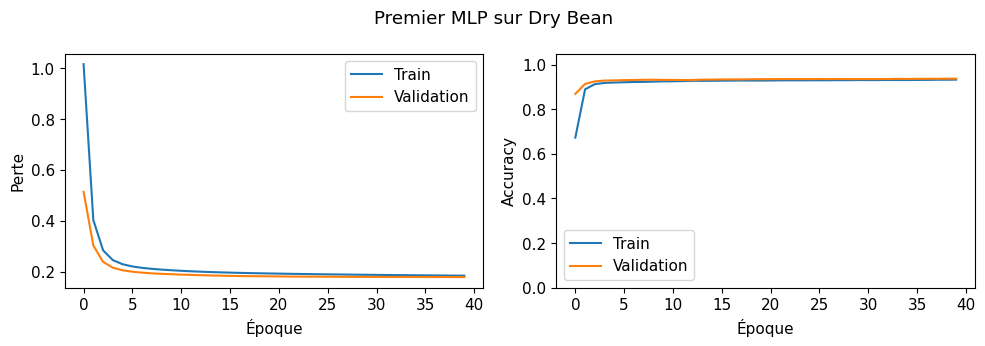

In [8]:
# fonction pratique pour tracer les courbes de loss et d'accuracy (train vs validation)
def plot_history(history, title):

    # dictionnaire qui contient l'historique des metriques
    h = history.history

    # on cree une figure avec 2 graphes cote a cote
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

    # premier graphe : la perte (loss) qui doit diminuer
    axes[0].plot(h["loss"], label="Train")
    axes[0].plot(h["val_loss"], label="Validation")
    axes[0].set(xlabel="Époque", ylabel="Perte")

    # deuxieme graphe : l'accuracy qui doit augmenter vers 1
    axes[1].plot(h["accuracy"], label="Train")
    axes[1].plot(h["val_accuracy"], label="Validation")
    axes[1].set(xlabel="Époque", ylabel="Accuracy", ylim=(0, 1.05))

    # afficher la legende sur les 2 graphes
    for ax in axes:
        ax.legend()

    # titre de la figure
    fig.suptitle(title)

    # bien caler les graphes pour pas que les textes se chevauchent
    plt.tight_layout()

    plt.show()


# on trace les courbes de notre premier MLP
plot_history(history, "Premier MLP sur Dry Bean")

Évaluation : {'accuracy': 0.9371785521507263, 'loss': 0.1784835010766983}
Probabilités : (2722, 7)
              precision    recall  f1-score   support

    BARBUNYA      0.935     0.924     0.930       264
      BOMBAY      1.000     1.000     1.000       105
        CALI      0.933     0.933     0.933       326
    DERMASON      0.927     0.944     0.935       709
       HOROZ      0.959     0.959     0.959       386
       SEKER      0.980     0.963     0.971       405
        SIRA      0.895     0.890     0.892       527

    accuracy                          0.937      2722
   macro avg      0.947     0.945     0.946      2722
weighted avg      0.937     0.937     0.937      2722



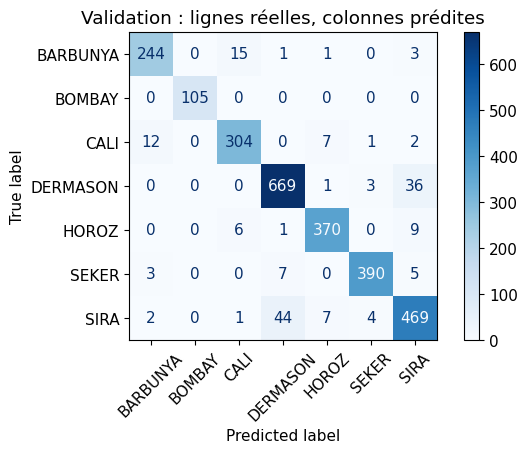

In [9]:
# evaluation du modele sur le jeu de validation
val_scores = model.evaluate(X_val_s, y_val, verbose=0, return_dict=True)
# predict renvoie les 7 probabilites pour chaque exemple de validation
prob_val = model.predict(X_val_s, verbose=0)
# argmax prend l'indice de la plus grande probabilite (la classe predite)
pred_val = np.argmax(prob_val, axis=1)

print("Évaluation :", val_scores)
print("Probabilités :", prob_val.shape)
# on verifie que la somme des probabilites de softmax fait bien 1 sur chaque ligne
assert np.allclose(prob_val.sum(axis=1), 1, atol=1e-5)

# rapport complet avec precision, recall et f1-score pour chaque type de haricot
print(classification_report(y_val, pred_val, target_names=class_names, digits=3))
# matrice de confusion pour voir ou le modele se trompe le plus (ex: entre SIRA et DERMASON)
cm_val = confusion_matrix(y_val, pred_val, labels=np.arange(n_classes))
ConfusionMatrixDisplay(cm_val, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Validation : lignes réelles, colonnes prédites")
plt.show()

In [10]:
# fonction generique pour creer facilement plein de modeles MLP avec differents hyperparametres
def create_model(
    hidden=(32,), activation="relu", rate=0.001,
    optimizer="adam", penalty=None, dropout=0.0, batchnorm=False,
    input_dim=n_features, n_classes=n_classes
):
    # on remet le seed a chaque creation pour comparer equitablement les modeles
    keras.utils.set_random_seed(SEED)

    # initialisation du reseau avec la couche d'entree
    net = keras.Sequential([keras.Input(shape=(input_dim,))])

    # boucle pour ajouter une ou plusieurs couches cachees
    for units in hidden:
        # couche dense avec penalite L1/L2 si on en passe une
        net.add(layers.Dense(units, kernel_regularizer=penalty))

        # si batchnorm est True on normalise avant l'activation
        if batchnorm:
            net.add(layers.BatchNormalization())

        # fonction d'activation (relu ou tanh)
        net.add(layers.Activation(activation))

        # si on a mis du dropout, sa coupe une partie des neurones au hasard pendant le train
        if dropout > 0:
            net.add(layers.Dropout(dropout))

    # couche de sortie softmax a 7 classes
    net.add(layers.Dense(n_classes, activation="softmax"))

    # choix de l'optimiseur (adam ou sgd classique)
    opt = (
        keras.optimizers.Adam(learning_rate=rate)
        if optimizer == "adam"
        else keras.optimizers.SGD(learning_rate=rate)
    )

    # on compile le reseau
    net.compile(
        optimizer=opt,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return net


# fonction de cout pour calculer la cross-entropie pure sur la validation (sans penalite L1/L2)
validation_loss = keras.losses.SparseCategoricalCrossentropy()


# fonction pour resumer les score d'un modele dans un dico
def summarize(name, net, hist):

    # probabilites predites sur validation
    proba = net.predict(X_val_s, verbose=0)

    # classe choisie (la proba max)
    pred = proba.argmax(axis=1)

    # on retourne un dictionnaire avec toute les infos utiles pour comparer
    return {
        "modèle": name,

        "paramètres": net.count_params(),  # nombre de parametres du reseau

        "époques": len(hist.history["loss"]),  # nb d'epoques faites

        # cross-entropie sur validation
        "CE_validation": float(
            validation_loss(y_val, proba).numpy()
        ),

        # accuracy sur validation
        "accuracy_validation": accuracy_score(y_val, pred),

        # F1 macro (moyenne des F1 de chaque classe, important car les classes sont desequilibrees)
        "F1_macro_validation": f1_score(
            y_val, pred, average="macro"
        )
    }

{'modèle': 'Adam, taux=0.0001', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.22442062199115753, 'accuracy_validation': 0.9268919911829537, 'F1_macro_validation': 0.937991888557919}
{'modèle': 'Adam, taux=0.001', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.1791355162858963, 'accuracy_validation': 0.9353416605437178, 'F1_macro_validation': 0.9440528858825376}
{'modèle': 'Adam, taux=0.05', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.22222593426704407, 'accuracy_validation': 0.9287288758265981, 'F1_macro_validation': 0.9378875194399644}


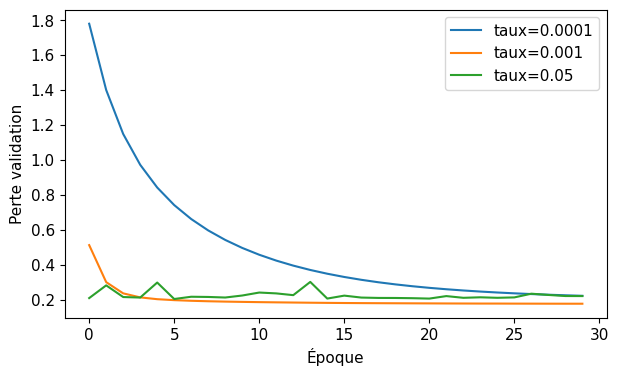

In [11]:
# dictionnaire pour garder les resultats selon le learning rate
rate_runs = {}

# on teste 3 learning rates : un petit (0.0001), un moyen (0.001) et un grand (0.05)
for eta in [0.0001, 0.001, 0.05]:

    # creation du modele avec ce taux d'apprentissage
    net = create_model(rate=eta)

    # entrainement sur 30 epoques
    hist = net.fit(
        X_train_s, y_train,
        validation_data=(X_val_s, y_val),
        epochs=30,
        batch_size=32,
        verbose=0
    )

    # sauvegarde dans le dico
    rate_runs[eta] = (net, hist)

    # afficher le resume des performances
    print(summarize(f"Adam, taux={eta}", net, hist))

    # ajouter la courbe de val_loss sur le meme graphique
    plt.plot(hist.history["val_loss"], label=f"taux={eta}")

# titres des axes et legende
plt.xlabel("Époque")
plt.ylabel("Perte validation")
plt.legend()
# on voit que 0.0001 apprend trop lentement, 0.05 est instable, et 0.001 est le meilleur
plt.show()

In [12]:
# comparaison entre les optimiseurs Adam et SGD
optimizer_runs = {}

# on boucle sur les 2 optimiseurs avec le meme learning rate 0.001
for opt in ["adam", "sgd"]:

    net = create_model(rate=0.001, optimizer=opt)

    # entrainement sur 30 epoques
    hist = net.fit(
        X_train_s, y_train,
        validation_data=(X_val_s, y_val),
        epochs=30,
        batch_size=32,
        verbose=0
    )

    optimizer_runs[opt] = (net, hist)

    # on remarque qu'avec lr=0.001 Adam converge beaucoup plus vite que SGD
    print(summarize(opt, net, hist))

{'modèle': 'adam', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.1791355162858963, 'accuracy_validation': 0.9353416605437178, 'F1_macro_validation': 0.9440528858825376}
{'modèle': 'sgd', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.45739132165908813, 'accuracy_validation': 0.8986039676708303, 'F1_macro_validation': 0.9127455166665006}


In [13]:
# test de l'impact du batch_size (taille de lot) avec SGD
batch_runs = {}

# on teste batch=1 (stochastique pur), batch=32 (mini-batch), et tout le train d'un coup (batch complet = 8166)
for size in [1, 32, len(y_train)]:

    # on met lr=0.01 pour que SGD avance un peu mieux
    net = create_model(rate=0.01, optimizer="sgd")

    # seulement 10 epoques car batch_size=1 est assez lent a tourner
    hist = net.fit(
        X_train_s, y_train,
        validation_data=(X_val_s, y_val),
        epochs=10,
        batch_size=size,
        verbose=0
    )

    batch_runs[size] = (net, hist)

    print(summarize(f"SGD, lot={size}", net, hist))

    # affiche combien de fois les poids sont mis a jour dans une seule epoque
    # avec lot=8166 il y a seulement 1 mise a jour par epoque donc le modele n'apprend presque rien en 10 epoques !
    print("Mises à jour par époque :", int(np.ceil(len(y_train) / size)))

{'modèle': 'SGD, lot=1', 'paramètres': 775, 'époques': 10, 'CE_validation': 0.18420544266700745, 'accuracy_validation': 0.9338721528288023, 'F1_macro_validation': 0.9435933096670807}
Mises à jour par époque : 8166
{'modèle': 'SGD, lot=32', 'paramètres': 775, 'époques': 10, 'CE_validation': 0.24625104665756226, 'accuracy_validation': 0.9261572373254959, 'F1_macro_validation': 0.9373532043967572}
Mises à jour par époque : 256
{'modèle': 'SGD, lot=8166', 'paramètres': 775, 'époques': 10, 'CE_validation': 2.153029680252075, 'accuracy_validation': 0.022777369581190303, 'F1_macro_validation': 0.01857896525460564}
Mises à jour par époque : 1


In [14]:
# comparaison de plusieur architectures et fonctions d'activation
architecture_runs = {}

# on teste : un reseau trop petit (2 neurones), le modele de base (32), un plus profond (64, 32) et tanh
for name, hidden, activation in [
    ("étroit", (2,), "relu"),          # goulot d'etranglement : 2 neurones c'est pas assez (sous-apprentissage)
    ("référence", (32,), "relu"),      # notre base a 32 neurones
    ("deux couches", (64, 32), "relu"), # 2 couches cachees : gagne un peu en performance
    ("tanh", (32,), "tanh")            # activation tanh a la place de relu
]:

    net = create_model(hidden=hidden, activation=activation)

    hist = net.fit(
        X_train_s, y_train,
        validation_data=(X_val_s, y_val),
        epochs=30,
        batch_size=32,
        verbose=0
    )

    architecture_runs[name] = (net, hist)

    # affiche les resultats pour voir quelle architecture marche le mieux
    print(summarize(name, net, hist))

{'modèle': 'étroit', 'paramètres': 55, 'époques': 30, 'CE_validation': 0.34601786732673645, 'accuracy_validation': 0.9103600293901543, 'F1_macro_validation': 0.9161530629832253}
{'modèle': 'référence', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.1791355162858963, 'accuracy_validation': 0.9353416605437178, 'F1_macro_validation': 0.9440528858825376}
{'modèle': 'deux couches', 'paramètres': 3399, 'époques': 30, 'CE_validation': 0.18276962637901306, 'accuracy_validation': 0.9382806759735489, 'F1_macro_validation': 0.9466792370174787}
{'modèle': 'tanh', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.18017995357513428, 'accuracy_validation': 0.934974283614989, 'F1_macro_validation': 0.9438026846955491}


{'modèle': 'référence', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.18359825015068054, 'accuracy_validation': 0.93791329904482, 'F1_macro_validation': 0.9469339596168754}
Perte evaluate, pénalité éventuelle incluse : 0.18359807133674622
{'modèle': 'L1', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.17847295105457306, 'accuracy_validation': 0.9390154298310066, 'F1_macro_validation': 0.9476335223050648}
Perte evaluate, pénalité éventuelle incluse : 0.21005816757678986
{'modèle': 'L2', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.17877866327762604, 'accuracy_validation': 0.9364437913299045, 'F1_macro_validation': 0.9457788528996175}
Perte evaluate, pénalité éventuelle incluse : 0.20822863280773163
{'modèle': 'Dropout', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.1787683069705963, 'accuracy_validation': 0.9375459221160911, 'F1_macro_validation': 0.9465067102998835}
Perte evaluate, pénalité éventuelle incluse : 0.1787680983543396
{'modèle': 'BatchNorm', 

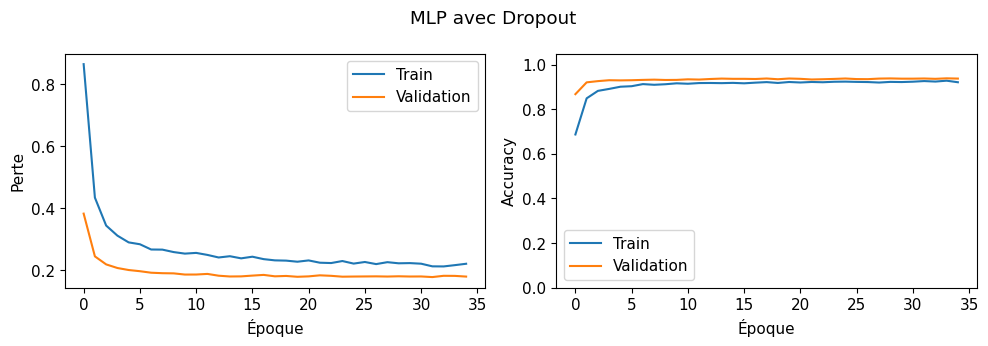

In [15]:
# test des differentes techniques de regularisation pour limiter le surapprentissage (overfitting)
regularization_runs = {}

# liste des configs a tester sur le reseau a 2 couches (64, 32)
configs = [
    ("référence", {}),  # sans regularisation

    # L1 : ajoute une penalite sur la valeur absolue des poids (pousse certains poids vers 0)
    ("L1", {"penalty": keras.regularizers.l1(0.0001)}),

    # L2 : penalise les poids trop grands (somme des carres)
    ("L2", {"penalty": keras.regularizers.l2(0.001)}),

    # Dropout : eteint 25% des neurones au hasard a chaque batch d'entrainement
    ("Dropout", {"dropout": 0.25}),

    # BatchNorm : normalise les sorties des couches cachees
    ("BatchNorm", {"batchnorm": True})
]

for name, options in configs:

    # on cree le modele (64, 32) avec l'option de regularisation
    net = create_model(hidden=(64, 32), **options)

    # entrainement sur 35 epoques
    hist = net.fit(
        X_train_s, y_train,
        validation_data=(X_val_s, y_val),
        epochs=35,
        batch_size=32,
        verbose=0
    )

    regularization_runs[name] = (net, hist)

    # summarize calcule la CE sans la penalite L1/L2
    print(summarize(name, net, hist))

    # alors que net.evaluate() inclut la penalite L1 ou L2 dans la loss totale !
    print(
        "Perte evaluate, pénalité éventuelle incluse :",
        net.evaluate(
            X_val_s, y_val,
            verbose=0,
            return_dict=True
        )["loss"]
    )

# on affiche les courbes pour le modele avec Dropout
plot_history(
    regularization_runs["Dropout"][1],
    "MLP avec Dropout"
)

In [16]:
# petite experience pour comprendre comment fonctionne le Dropout entre train et test

# on cree un petit reseau avec un gros dropout de 50%
probe = keras.Sequential([
    keras.Input(shape=(n_features,)),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.5), # 1 neurone sur 2 est desactive en mode training
    layers.Dense(n_classes, activation="softmax")
])

# en mode evaluation (training=False), le dropout est desactive donc 2 appels donnent exactement pareil
eval1 = probe(X_val_s[:8], training=False).numpy()
eval2 = probe(X_val_s[:8], training=False).numpy()

# en mode entrainement (training=True), les neurones coupes changent a chaque appel donc les sorties changent
train1 = probe(X_val_s[:8], training=True).numpy()
train2 = probe(X_val_s[:8], training=True).numpy()

# doit afficher True
print("Évaluation identique :", np.allclose(eval1, eval2))

# doit afficher False car le masque de dropout est aleatoire
print("Entraînement identique :", np.allclose(train1, train2))

Évaluation identique : True
Entraînement identique : False


Époques exécutées : 74
Meilleure époque : 66
{'accuracy': 0.9360764026641846, 'loss': 0.1774529367685318}


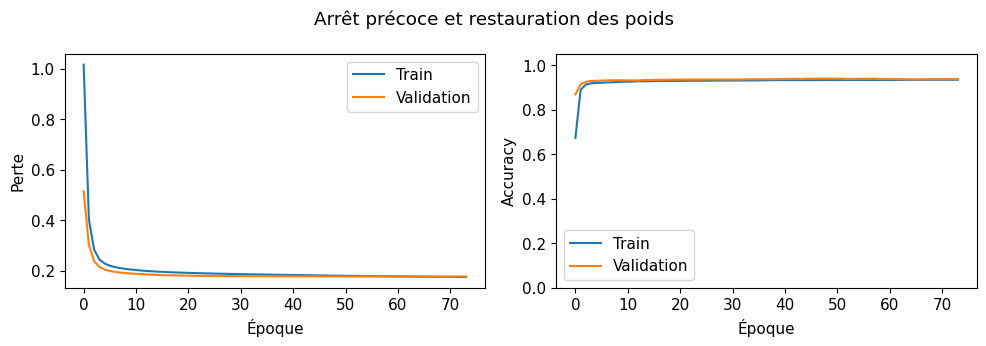

In [17]:
# utilisation de EarlyStopping pour arreter l'entrainement automatiquement quand val_loss stagne
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",             # on surveille la perte sur validation
    patience=8,                     # si sa s'ameliore pas pendant 8 epoques de suite, on stop
    min_delta=0,                    # meme une toute petite baisse compte comme une amelioration
    restore_best_weights=True       # super important : on recupere les poids de la meilleure epoque
)

early_model = create_model()

# on met 100 epoques max mais le callback va l'arreter avant
early_history = early_model.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)

# voir a quelle epoque il s'est arrete
print("Époques exécutées :", len(early_history.history["loss"]))

# l'epoque qui avait la meilleure val_loss (+1 parce que l'indice commence a 0)
print("Meilleure époque :", 1 + np.argmin(early_history.history["val_loss"]))

# score final du modele avec les meilleurs poids restaures
print(early_model.evaluate(
    X_val_s, y_val,
    verbose=0,
    return_dict=True
))

plot_history(early_history, "Arrêt précoce et restauration des poids")

In [18]:
# sauvegarde du modele et du preprocesseur pour pouvoir les reutiliser plus tard en production
import joblib
import json

# on sauvegarde le modele keras
early_model.save("modele_drybean.keras")

# il faut aussi sauvegarder le scaler sinon on pourra pas normaliser les nouvelles donnees correctement !
joblib.dump(scaler, "scaler_drybean.pkl")

# et on sauvegarde les noms des 7 classes dans un fichier json
with open("classes_drybean.json", "w") as f:
    json.dump(class_names, f)

# --- test de rechargement pour verifier que tout marche bien ---

loaded_model = keras.models.load_model("modele_drybean.keras")
scaler_loaded = joblib.load("scaler_drybean.pkl")

# predictions avec le modele en memoire sur les 5 premiers exemples deja normalises
p_before = early_model.predict(X_val_s[:5], verbose=0)

# predictions avec le modele recharge en normalisant les donnees brutes X_val[:5] avec le scaler recharge
p_after = loaded_model.predict(
    scaler_loaded.transform(X_val[:5]),
    verbose=0
)

# on verifie qu'on obtient exactement les memes probabilites (True)
print("Prédictions conservées :", np.allclose(p_before, p_after, atol=1e-5))

Prédictions conservées : True
